# Binary encoding performance across pLMs

Compare Spearman correlations between sequence relationships and binary-vector distances for AAV capsid surface region variants, using bVAE and pLM-bVAE models without hyperparameter optimization.

In [1]:
# Compare binary encoding performance across models using Spearman correlations for AAV capsid variants.
import pandas as pd
import re
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings("ignore")

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

## Load correlation results

In [2]:
# Load correlation data.
plm_res = "...\\pLM-bVAE\\reproduction_paper\\outputs\\"
# bvae
test_res_bvae = pd.read_csv(plm_res + "aav_models\\bvae\\model_output\\binary\\compare_results.csv", sep='\t', header=None, names=["line"])
lines = test_res_bvae["line"].astype(str).tolist()
corr_bvae = {}
current_section = None
for line in lines:
    line = line.strip()
    # Identify the current section.
    if line == "Levenshtein distance of test_seqs vs Hamming distance of binary vectors:":
        current_section = "Levenshtein_vs_Hamming"
        continue
    if line == "BLOSUM62 scores of test_seqs vs Hamming distance of binary vectors:":
        current_section = "BLOSUM62_vs_Hamming"
        continue
    # Extract the Pearson correlation for the modified model.
    m = re.search(r"Modified model Pearson corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_bvae[f"{current_section}_Modified_Pearson"] = float(m.group(1))
        continue
    # Extract the Spearman correlation for the modified model.
    m = re.search(r"Modified model Spearman corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_bvae[f"{current_section}_Modified_Spearman"] = float(m.group(1))
        continue
# esm_8m
test_res_esm_8m = pd.read_csv(plm_res + "aav_models\\esm_8m\\model_output\\binary\\compare_results.csv", sep='\t', header=None, names=["line"])
lines = test_res_esm_8m["line"].astype(str).tolist()
corr_esm_8m = {}
current_section = None
for line in lines:
    line = line.strip()
    # Identify the current section.
    if line == "Levenshtein distance of test_seqs vs Hamming distance of binary vectors:":
        current_section = "Levenshtein_vs_Hamming"
        continue
    if line == "BLOSUM62 scores of test_seqs vs Hamming distance of binary vectors:":
        current_section = "BLOSUM62_vs_Hamming"
        continue
    # Extract the Pearson correlation for the modified model.
    m = re.search(r"Modified model Pearson corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_esm_8m[f"{current_section}_Modified_Pearson"] = float(m.group(1))
        continue
    # Extract the Spearman correlation for the modified model.
    m = re.search(r"Modified model Spearman corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_esm_8m[f"{current_section}_Modified_Spearman"] = float(m.group(1))
        continue
# esm_650m
test_res_esm_650m = pd.read_csv(plm_res + "aav_models\\esm_650m\\model_output\\binary\\compare_results.csv", sep='\t', header=None, names=["line"])
lines = test_res_esm_650m["line"].astype(str).tolist()
corr_esm_650m = {}
current_section = None
for line in lines:
    line = line.strip()
    # Identify the current section.
    if line == "Levenshtein distance of test_seqs vs Hamming distance of binary vectors:":
        current_section = "Levenshtein_vs_Hamming"
        continue
    if line == "BLOSUM62 scores of test_seqs vs Hamming distance of binary vectors:":
        current_section = "BLOSUM62_vs_Hamming"
        continue
    # Extract the Pearson correlation for the modified model.
    m = re.search(r"Modified model Pearson corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_esm_650m[f"{current_section}_Modified_Pearson"] = float(m.group(1))
        continue
    # Extract the Spearman correlation for the modified model.
    m = re.search(r"Modified model Spearman corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_esm_650m[f"{current_section}_Modified_Spearman"] = float(m.group(1))
        continue
# esm_3b
test_res_esm_3b = pd.read_csv(plm_res + "aav_models\\esm_3b\\model_output\\binary\\compare_results.csv", sep='\t', header=None, names=["line"])
lines = test_res_esm_3b["line"].astype(str).tolist()
corr_esm_3b = {}
current_section = None
for line in lines:
    line = line.strip()
    # Identify the current section.
    if line == "Levenshtein distance of test_seqs vs Hamming distance of binary vectors:":
        current_section = "Levenshtein_vs_Hamming"
        continue
    if line == "BLOSUM62 scores of test_seqs vs Hamming distance of binary vectors:":
        current_section = "BLOSUM62_vs_Hamming"
        continue
    # Extract the Pearson correlation for the modified model.
    m = re.search(r"Modified model Pearson corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_esm_3b[f"{current_section}_Modified_Pearson"] = float(m.group(1))
        continue
    # Extract the Spearman correlation for the modified model.
    m = re.search(r"Modified model Spearman corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_esm_3b[f"{current_section}_Modified_Spearman"] = float(m.group(1))
        continue
# prott5
test_res_prott5 = pd.read_csv(plm_res + "aav_models\\prott5\\model_output\\binary\\compare_results.csv", sep='\t', header=None, names=["line"])
lines = test_res_prott5["line"].astype(str).tolist()
corr_prott5 = {}
current_section = None
for line in lines:
    line = line.strip()
    # Identify the current section.
    if line == "Levenshtein distance of test_seqs vs Hamming distance of binary vectors:":
        current_section = "Levenshtein_vs_Hamming"
        continue
    if line == "BLOSUM62 scores of test_seqs vs Hamming distance of binary vectors:":
        current_section = "BLOSUM62_vs_Hamming"
        continue
    # Extract the Pearson correlation for the modified model.
    m = re.search(r"Modified model Pearson corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_prott5[f"{current_section}_Modified_Pearson"] = float(m.group(1))
        continue
    # Extract the Spearman correlation for the modified model.
    m = re.search(r"Modified model Spearman corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_prott5[f"{current_section}_Modified_Spearman"] = float(m.group(1))
        continue
# prostt5
test_res_prostt5 = pd.read_csv(plm_res + "aav_models\\prostt5\\model_output\\binary\\compare_results.csv", sep='\t', header=None, names=["line"])
lines = test_res_prostt5["line"].astype(str).tolist()
corr_prostt5 = {}
current_section = None
for line in lines:
    line = line.strip()
    # Identify the current section.
    if line == "Levenshtein distance of test_seqs vs Hamming distance of binary vectors:":
        current_section = "Levenshtein_vs_Hamming"
        continue
    if line == "BLOSUM62 scores of test_seqs vs Hamming distance of binary vectors:":
        current_section = "BLOSUM62_vs_Hamming"
        continue
    # Extract the Pearson correlation for the modified model.
    m = re.search(r"Modified model Pearson corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_prostt5[f"{current_section}_Modified_Pearson"] = float(m.group(1))
        continue
    # Extract the Spearman correlation for the modified model.
    m = re.search(r"Modified model Spearman corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_prostt5[f"{current_section}_Modified_Spearman"] = float(m.group(1))
        continue
# ankh_base
test_res_ankh_base = pd.read_csv(plm_res + "aav_models\\ankh_base\\model_output\\binary\\compare_results.csv", sep='\t', header=None, names=["line"])
lines = test_res_ankh_base["line"].astype(str).tolist()
corr_ankh_base = {}
current_section = None
for line in lines:
    line = line.strip()
    # Identify the current section.
    if line == "Levenshtein distance of test_seqs vs Hamming distance of binary vectors:":
        current_section = "Levenshtein_vs_Hamming"
        continue
    if line == "BLOSUM62 scores of test_seqs vs Hamming distance of binary vectors:":
        current_section = "BLOSUM62_vs_Hamming"
        continue
    # Extract the Pearson correlation for the modified model.
    m = re.search(r"Modified model Pearson corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_ankh_base[f"{current_section}_Modified_Pearson"] = float(m.group(1))
        continue
    # Extract the Spearman correlation for the modified model.
    m = re.search(r"Modified model Spearman corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_ankh_base[f"{current_section}_Modified_Spearman"] = float(m.group(1))
        continue
# ankh_large
test_res_ankh_large = pd.read_csv(plm_res + "aav_models\\ankh_large\\model_output\\binary\\compare_results.csv", sep='\t', header=None, names=["line"])
lines = test_res_ankh_large["line"].astype(str).tolist()
corr_ankh_large = {}
current_section = None
for line in lines:
    line = line.strip()
    # Identify the current section.
    if line == "Levenshtein distance of test_seqs vs Hamming distance of binary vectors:":
        current_section = "Levenshtein_vs_Hamming"
        continue
    if line == "BLOSUM62 scores of test_seqs vs Hamming distance of binary vectors:":
        current_section = "BLOSUM62_vs_Hamming"
        continue
    # Extract the Pearson correlation for the modified model.
    m = re.search(r"Modified model Pearson corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_ankh_large[f"{current_section}_Modified_Pearson"] = float(m.group(1))
        continue
    # Extract the Spearman correlation for the modified model.
    m = re.search(r"Modified model Spearman corr:\s*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)", line)
    if m and current_section is not None:
        corr_ankh_large[f"{current_section}_Modified_Spearman"] = float(m.group(1))
        continue

In [3]:
corr_ankh_large

{'Levenshtein_vs_Hamming_Modified_Pearson': 0.43337868002334196,
 'Levenshtein_vs_Hamming_Modified_Spearman': 0.4389622399961491,
 'BLOSUM62_vs_Hamming_Modified_Pearson': -0.4937612349059587,
 'BLOSUM62_vs_Hamming_Modified_Spearman': -0.5034771061450527}

## Levenshtein and Hamming distances

In [4]:
# Create a table of Spearman correlations between Levenshtein and Hamming distances.
corr_spe_Lev_df = pd.DataFrame({
    "model": ["bvae", "esm_8m", "esm_650m", "esm_3b", "prott5", "prostt5", "ankh_base", "ankh_large"],
    "spearman_Lev": [corr_bvae["Levenshtein_vs_Hamming_Modified_Spearman"], corr_esm_8m["Levenshtein_vs_Hamming_Modified_Spearman"], corr_esm_650m["Levenshtein_vs_Hamming_Modified_Spearman"], corr_esm_3b["Levenshtein_vs_Hamming_Modified_Spearman"], corr_prott5["Levenshtein_vs_Hamming_Modified_Spearman"], corr_prostt5["Levenshtein_vs_Hamming_Modified_Spearman"], corr_ankh_base["Levenshtein_vs_Hamming_Modified_Spearman"], corr_ankh_large["Levenshtein_vs_Hamming_Modified_Spearman"]],
})

In [5]:
corr_spe_Lev_df

,model,spearman_Lev
0,bvae,0.104388
1,esm_8m,0.451944
2,esm_650m,0.550175
3,esm_3b,0.336090
4,prott5,0.499368
5,prostt5,0.417377
6,ankh_base,0.485289
7,ankh_large,0.438962


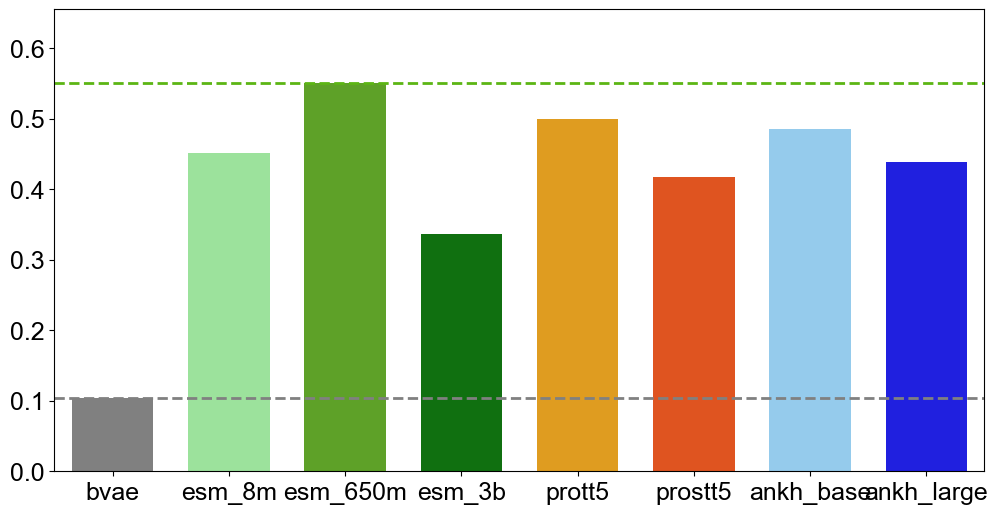

In [6]:
# Plot the Spearman correlations for Levenshtein and Hamming distances.
# Use consistent colors for each model.
plt.figure(figsize=(12, 6))
sns.barplot(x="model", y="spearman_Lev", data=corr_spe_Lev_df, palette=["gray", "lightgreen", "#5CB514", "green", "orange", "#ff4500", "lightskyblue", "blue"], width=0.7)
# Show the bVAE result as a horizontal reference line.
bvae_value = corr_spe_Lev_df[corr_spe_Lev_df["model"] == "bvae"]["spearman_Lev"].values[0]
plt.axhline(y=bvae_value, color='gray', linestyle='--', linewidth=2)
# Show the ESM2 650M result as a horizontal reference line.
esm_650m_value = corr_spe_Lev_df[corr_spe_Lev_df["model"] == "esm_650m"]["spearman_Lev"].values[0]
plt.axhline(y=esm_650m_value, color='#5CB514', linestyle='--', linewidth=2)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.ylim(0, 0.655)
plt.xlabel("")
plt.ylabel("")
plt.show()

## BLOSUM62 scores and Hamming distances

In [7]:
# Create a table of Spearman correlations between BLOSUM62 scores and Hamming distances.
corr_spe_bs62_df = pd.DataFrame({
    "model": ["bvae", "esm_8m", "esm_650m", "esm_3b", "prott5", "prostt5", "ankh_base", "ankh_large"],
    "spearman_bs62": [corr_bvae["BLOSUM62_vs_Hamming_Modified_Spearman"], corr_esm_8m["BLOSUM62_vs_Hamming_Modified_Spearman"], corr_esm_650m["BLOSUM62_vs_Hamming_Modified_Spearman"], corr_esm_3b["BLOSUM62_vs_Hamming_Modified_Spearman"], corr_prott5["BLOSUM62_vs_Hamming_Modified_Spearman"], corr_prostt5["BLOSUM62_vs_Hamming_Modified_Spearman"], corr_ankh_base["BLOSUM62_vs_Hamming_Modified_Spearman"], corr_ankh_large["BLOSUM62_vs_Hamming_Modified_Spearman"]],
})

In [8]:
corr_spe_bs62_df

,model,spearman_bs62
0,bvae,-0.167983
1,esm_8m,-0.552152
2,esm_650m,-0.604452
3,esm_3b,-0.480772
4,prott5,-0.595489
5,prostt5,-0.533843
6,ankh_base,-0.558679
7,ankh_large,-0.503477


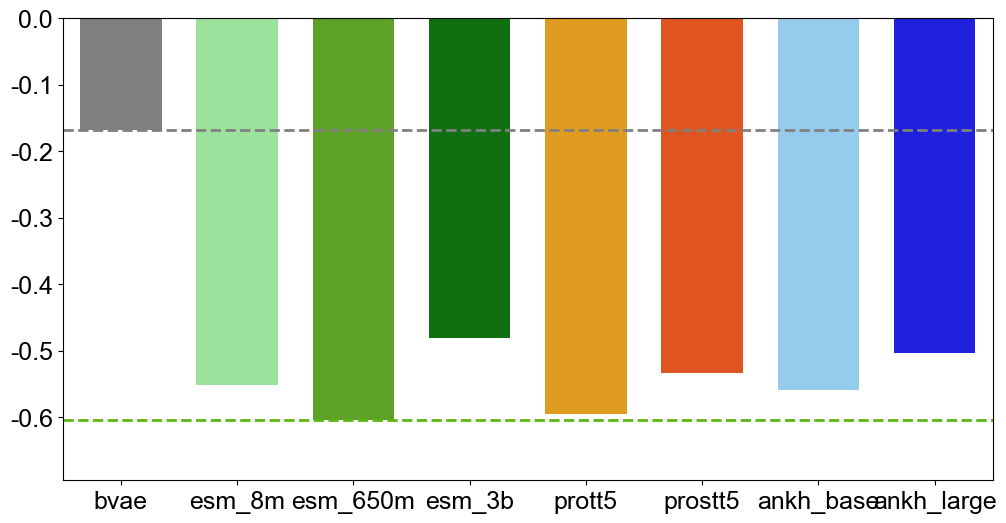

In [9]:
# Plot the Spearman correlations for BLOSUM62 scores and Hamming distances.
# Use consistent colors for each model.
plt.figure(figsize=(12, 6))
sns.barplot(x="model", y="spearman_bs62", data=corr_spe_bs62_df, palette=["gray", "lightgreen", "#5CB514", "green", "orange", "#ff4500", "lightskyblue", "blue"], width=0.7)
# Show the bVAE result as a horizontal reference line.
bvae_value = corr_spe_bs62_df[corr_spe_bs62_df["model"] == "bvae"]["spearman_bs62"].values[0]
plt.axhline(y=bvae_value, color='gray', linestyle='--', linewidth=2)
# Show the ESM2 650M result as a horizontal reference line.
esm_650m_value = corr_spe_bs62_df[corr_spe_bs62_df["model"] == "esm_650m"]["spearman_bs62"].values[0]
plt.axhline(y=esm_650m_value, color='#5CB514', linestyle='--', linewidth=2)

plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.ylim(-0.695, 0)
plt.xlabel("")
plt.ylabel("")
plt.show()